Dataset Shape: (1000, 16)

First 5 Records:
   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1000 non-null   int64
 1   Gender                   1000 non-null   object
 2   Cholesterol              1000 non-null   int64
 3   Blood Pressure           1000 non-null   int64
 4   Heart Rate               1000 non-null   int64
 5   Smoking                  1000 non-null   object
 6   Alcohol Intake           660 non-null    object
 7   Exercise Ho

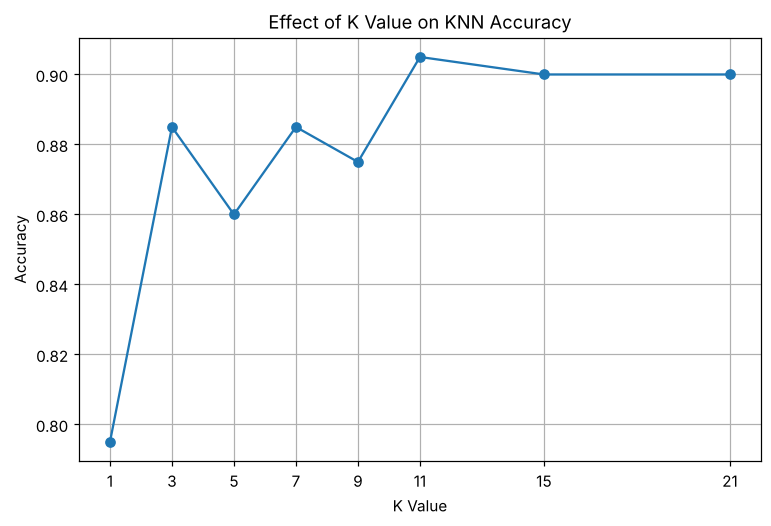

Best K: 11
Best Accuracy: 0.905
Best Precision: 0.9154929577464789
Best Recall: 0.8333333333333334
Best F1 Score: 0.87248322147651

FINAL KNN MODEL
Best K       : 11
Accuracy     : 0.905
Precision    : 0.9154929577464789
Recall       : 0.8333333333333334
F1 Score     : 0.87248322147651
Specificity  : 0.9508196721311475
AUC          : 0.9550756620428752


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Heart Disease"].value_counts())

X = df.drop("Heart Disease", axis=1)

y = df["Heart Disease"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data :", X_test.shape)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

K = 5
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train_processed,
    y_train
)

y_pred = knn.predict(
    X_test_processed
)

print("Predicted Values:")
print(y_pred[:20])

print(
    classification_report(
        y_test,
        y_pred
    )
)

k_values = [1, 3, 5, 7, 9, 11, 15, 21]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_processed,
        y_train
    )

    y_pred = knn.predict(
        X_test_processed
    )

    accuracy_values.append(
        accuracy_score(
            y_test,
            y_pred
        )
    )

    precision_values.append(
        precision_score(
            y_test,
            y_pred
        )
    )

    recall_values.append(
        recall_score(
            y_test,
            y_pred
        )
    )

    f1_values.append(
        f1_score(
            y_test,
            y_pred
        )
    )

results = pd.DataFrame({
    "K": k_values,
    "Accuracy": accuracy_values,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1 Score": f1_values
})

print(results)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy")

plt.title("Effect of K Value on KNN Accuracy")

plt.xticks(k_values)

plt.grid()

plt.show()

best_index = np.argmax(f1_values)

best_k = k_values[best_index]

print("Best K:", best_k)

print(
    "Best Accuracy:",
    accuracy_values[best_index]
)

print(
    "Best Precision:",
    precision_values[best_index]
)

print(
    "Best Recall:",
    recall_values[best_index]
)

print(
    "Best F1 Score:",
    f1_values[best_index]
)

final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(
    X_train_processed,
    y_train
)

final_pred = final_knn.predict(
    X_test_processed
)

final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred
)

final_recall = recall_score(
    y_test,
    final_pred
)

final_f1 = f1_score(
    y_test,
    final_pred
)

final_cm = confusion_matrix(
    y_test,
    final_pred
)

TN, FP, FN, TP = final_cm.ravel()

final_specificity = TN / (TN + FP)

final_probability = final_knn.predict_proba(
    X_test_processed
)[:, 1]

final_auc = roc_auc_score(
    y_test,
    final_probability
)

print("\n======================================")
print("FINAL KNN MODEL")
print("======================================")

print("Best K       :", best_k)
print("Accuracy     :", final_accuracy)
print("Precision    :", final_precision)
print("Recall       :", final_recall)
print("F1 Score     :", final_f1)
print("Specificity  :", final_specificity)
print("AUC          :", final_auc)
